# Music Analysis with Pandas

Billboard + Spotify data from Kaggle   
- | https://www.kaggle.com/datasets/ludmin/billboard | 
- | https://www.kaggle.com/datasets/nelgiriyewithana/most-streamed-spotify-songs-2024  | 
- | https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

## Load & Combine Data

In [2]:
hot100 = pd.read_csv('datasets/hot100.csv', low_memory=False) # mixed datatypes in the chuncks
billboard200 = pd.read_csv('datasets/billboard200.csv', low_memory=False)
streaming = pd.read_csv('datasets/streaming.csv')
spotify = pd.read_csv('datasets/SpotifyTrackDataset.csv')

hot100['chart'] = 'Hot100'
billboard200['chart'] = 'Billboard200'
streaming['chart'] = 'Streaming'
            # key word to remember "dataframes"
charts = pd.concat([hot100, billboard200, streaming], ignore_index=True)

print(f'Total rows: {len(charts)}')
charts.head()

Total rows: 1040477


,Date,Song,Artist,Rank,Last Week,Peak Position,Weeks in Charts,Image URL,chart
0,1958-07-30,Poor Little Fool,Ricky Nelson,1,-,1,1,NaN,Hot100
1,1958-07-30,Patricia,Perez Prado And His Orchestra,2,-,2,1,NaN,Hot100
2,1958-07-30,Splish Splash,Bobby Darin,3,-,3,1,NaN,Hot100
3,1958-07-30,Hard Headed Woman,Elvis Presley With The Jordanaires,4,-,4,1,https://charts-static.billboard.com/img/1958/0...,Hot100
4,1958-07-30,When,Kalin Twins,5,-,5,1,NaN,Hot100


## Clean Data

In [3]:
charts['Date'] = pd.to_datetime(charts['Date'], errors='coerce')
charts['year'] = charts['Date'].dt.year
charts['Rank'] = pd.to_numeric(charts['Rank'], errors='coerce')
charts = charts.drop_duplicates(subset=['Song', 'Artist', 'Date', 'chart'])

print(f'After cleaning: {len(charts)} rows')
charts.head()

After cleaning: 1040408 rows


,Date,Song,Artist,Rank,Last Week,Peak Position,Weeks in Charts,Image URL,chart,year
0,1958-07-30,Poor Little Fool,Ricky Nelson,1,-,1,1,NaN,Hot100,1958
1,1958-07-30,Patricia,Perez Prado And His Orchestra,2,-,2,1,NaN,Hot100,1958
2,1958-07-30,Splish Splash,Bobby Darin,3,-,3,1,NaN,Hot100,1958
3,1958-07-30,Hard Headed Woman,Elvis Presley With The Jordanaires,4,-,4,1,https://charts-static.billboard.com/img/1958/0...,Hot100,1958
4,1958-07-30,When,Kalin Twins,5,-,5,1,NaN,Hot100,1958


## Summary by Chart Type

In [4]:
summary = charts.groupby('chart').agg(
    total=('Song', 'count'),
    artists=('Artist', 'nunique'),
    avg_rank=('Rank', 'mean')
)
summary

,total,artists,avg_rank
chart,,,
Billboard200,649013,10403,99.368906
Hot100,355645,11266,50.501090
Streaming,35750,1861,25.500000


## Top Artists

In [5]:
top_artists = charts[charts['chart'] == 'Hot100']['Artist'].value_counts().head(10)
top_artists

Artist
Taylor Swift     1766
Drake            1147
Morgan Wallen    1093
Elton John        889
Madonna           857
Kenny Chesney     797
Tim McGraw        749
Keith Urban       674
Jason Aldean      672
Stevie Wonder     659
Name: count, dtype: int64

## Top Spotify Streamed Artists in 2024

In [6]:
most_streamed = pd.read_csv('datasets/MostStreamedSpotify2024.csv', encoding='latin-1')

most_streamed['Spotify Streams'] = (
    most_streamed['Spotify Streams']
    .astype(str)  # turned into text
    .str.replace(',', '', regex=False) # means its a comma not a expression
    .astype(float) # txt back into numbers
)

spotify_artists = most_streamed.groupby('Artist')['Spotify Streams'].sum().sort_values(ascending=False).head(10)
spotify_artists

Artist
Bad Bunny         3.705483e+10
The Weeknd        3.694854e+10
Drake             3.496216e+10
Taylor Swift      3.447077e+10
Post Malone       2.613747e+10
Ed Sheeran        2.401490e+10
Ariana Grande     2.346499e+10
MUSIC LAB JPN     2.286669e+10
Olivia Rodrigo    1.972922e+10
Eminem            1.887888e+10
Name: Spotify Streams, dtype: float64

## Most Popular Spotify Songs & Artists by Year


In [7]:
spotify_yearly = pd.read_csv('datasets/track_data_final.csv')

# Extract release year from album
spotify_yearly['year'] = pd.to_datetime(spotify_yearly['album_release_date'], errors='coerce').dt.year
spotify_yearly = spotify_yearly.dropna(subset=['year'])
spotify_yearly['year'] = spotify_yearly['year'].astype(int)

# Most popular song per year
top_song_by_year = (
    spotify_yearly.groupby(['year', 'track_name', 'artist_name'])['track_popularity']
    .max()
    .reset_index()
    .sort_values(['year', 'track_popularity'], ascending=[True, False])
    .groupby('year')
    .first()
    .reset_index()[['year', 'track_name', 'artist_name', 'track_popularity']]
)

# Most popular artist per year
artist_yearly = (
    spotify_yearly.groupby(['year', 'artist_name'])['artist_popularity']
    .mean()
    .reset_index()
    .sort_values(['year', 'artist_popularity'], ascending=[True, False])
    .groupby('year')
    .first()
    .reset_index()[['year', 'artist_name', 'artist_popularity']]
)
artist_yearly['artist_popularity'] = artist_yearly['artist_popularity'].round(1)

print(f'Years covered: {top_song_by_year["year"].min()} - {top_song_by_year["year"].max()}')
print('\nMost Popular Song by Year:')
print(top_song_by_year.to_string(index=False))
print('\nMost Popular Artist by Year:')
print(artist_yearly.to_string(index=False))


Years covered: 1952 - 2025

Most Popular Song by Year:
 year                                                 track_name                  artist_name  track_popularity
 1952                                         Alone And Forsaken                Hank Williams                45
 1958                                                  I'm A Man                   Bo Diddley                55
 1959                                            Johnny B. Goode                  Chuck Berry                74
 1960                                                   Misirlou                    Dick Dale                47
 1962                                                Stand By Me                  Ben E. King                77
 1964                                          You Really Got Me                    The Kinks                71
 1965                                                    My Girl              The Temptations                79
 1966                                            

## Most Persistent Songs

In [8]:
charts['Song'] = charts['Song'].astype(str).str.strip()
charts['Artist'] = charts['Artist'].astype(str).str.strip()
charts['chart'] = charts['chart'].astype(str).str.strip()

charts['Weeks in Charts'] = pd.to_numeric(
    charts['Weeks in Charts'].astype(str).str.replace(',', '', regex=False), 
    errors='coerce'
)

top_weeks = (
    charts.groupby(['Song', 'Artist', 'chart'], as_index=False)['Weeks in Charts']
    .max()
    .sort_values('Weeks in Charts', ascending=False)
    .head(10)
)
top_weeks[['Song', 'Artist', 'chart', 'Weeks in Charts']]

,Song,Artist,chart,Weeks in Charts
62792,The Dark Side Of The Moon,Pink Floyd,Billboard200,996.0
36743,Legend: The Best Of Bob Marley And The Wailers,Bob Marley And The Wailers,Billboard200,955.0
34571,Journey's Greatest Hits,Journey,Billboard200,925.0
41873,Metallica,Metallica,Billboard200,848.0
13446,Chronicle: The 20 Greatest Hits,Creedence Clearwater Revival,Billboard200,814.0
15460,Curtain Call: The Hits,Eminem,Billboard200,804.0
18259,Doo-Wops & Hooligans,Bruno Mars,Billboard200,796.0
44710,Nevermind,Nirvana,Billboard200,790.0
25551,Greatest Hits,Guns N' Roses,Billboard200,789.0
67475,Thriller,Michael Jackson,Billboard200,734.0


## 7. Yearly Activity

In [9]:
year_counts = charts['year'].value_counts().sort_index()
print('Chart entries per year (combined):')
print(year_counts)

# Break down by chart: the three charts have different coverage, so the combined

yearly_by_chart = charts.groupby(['year', 'chart']).size().unstack(fill_value=0)
print('\nChart entries per year, broken down by chart:')
print(yearly_by_chart)


Chart entries per year (combined):
year
1958     2291
1959     5200
1960     5199
1961     5194
1962     5200
        ...  
2022    18200
2023    18200
2024    18200
2025    18550
2026    13300
Name: count, Length: 69, dtype: int64

Chart entries per year, broken down by chart:
chart  Billboard200  Hot100  Streaming
year                                  
1958              0    2291          0
1959              0    5200          0
1960              0    5199          0
1961              0    5194          0
1962              0    5200          0
...             ...     ...        ...
2022          10400    5200       2600
2023          10400    5200       2600
2024          10400    5200       2600
2025          10600    5300       2650
2026           7600    3800       1900

[69 rows x 3 columns]


## 8. Top 10 Songs by Best Rank

In [10]:
top_ranked = charts.nsmallest(10, 'Rank')[['Song', 'Artist', 'chart', 'Rank', 'year']]
top_ranked

,Song,Artist,chart,Rank,year
0,Poor Little Fool,Ricky Nelson,Hot100,1,1958
97,Poor Little Fool,Ricky Nelson,Hot100,1,1958
195,Nel Blu Dipinto Di Blu (Volare),Domenico Modugno,Hot100,1,1958
292,Little Star,The Elegants,Hot100,1,1958
391,Nel Blu Dipinto Di Blu (Volare),Domenico Modugno,Hot100,1,1958
491,Nel Blu Dipinto Di Blu (Volare),Domenico Modugno,Hot100,1,1958
591,Nel Blu Dipinto Di Blu (Volare),Domenico Modugno,Hot100,1,1958
691,Nel Blu Dipinto Di Blu (Volare),Domenico Modugno,Hot100,1,1958
791,It's All In The Game,Tommy Edwards,Hot100,1,1958
891,It's All In The Game,Tommy Edwards,Hot100,1,1958


## 9. Graphs & Save

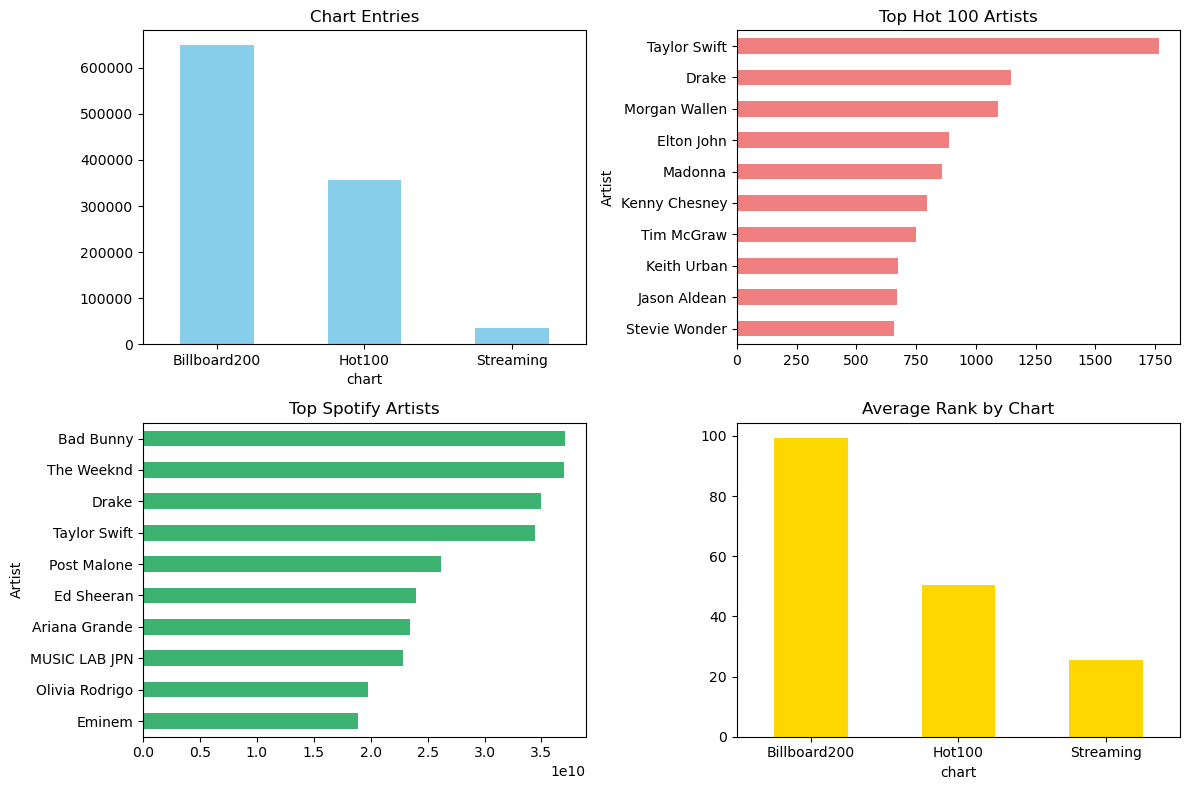

Saved cleaned_charts.csv


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

charts['chart'].value_counts().plot(kind='bar', ax=axes[0,0], color='skyblue', title='Chart Entries')
axes[0,0].tick_params(axis='x', rotation=0)

top_artists.plot(kind='barh', ax=axes[0,1], color='lightcoral', title='Top Hot 100 Artists')
axes[0,1].invert_yaxis()

spotify_artists.plot(kind='barh', ax=axes[1,0], color='mediumseagreen', title='Top Spotify Artists')
axes[1,0].invert_yaxis()

summary['avg_rank'].plot(kind='bar', ax=axes[1,1], color='gold', title='Average Rank by Chart')
axes[1,1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()
                                        # fun fact: if dataframe is base zero pandas will print numbers 
charts.to_csv('cleaned_charts.csv', index=False) # to prevent printing the row numbers with the charts
print('Saved cleaned_charts.csv')

cleaned_charts.csv gets saved to the workspace.